# 01 · Problem framing, data audit and EDA
**ProSit 2 · ICS553 Machine Learning Essentials · NkwaPay, Kenya → Ghana**

This notebook covers **Part A** (problem framing, label, feature audit, cost matrix) and **Part B.1–B.2**
(EDA, preprocessing decisions, time-safe feature engineering). It fits **no models**.

| Notebook | Covers |
|---|---|
| **01_eda** (this) | Part A framing + cost matrix, data audit, EDA, feature engineering checks |
| 02_classification | Task 2: default model, validation integrity, calibration, threshold, test, noise floor, reason codes |
| 03_regression | Task 1: loan-amount (limit) regression with residual diagnostics |
| 04_transfer_and_fairness | Part C transfer study, Part D fairness audit + model card + regulation, Part E scoring service |

All shared code lives in `src/prosit2/` so every notebook (and the scoring service) uses the same definitions.
Run the notebooks in order; see `README.md`.

### Running in Google Colab
Run the next cell first (it does nothing when you run locally). It mounts Google Drive, clones this repo into the Colab VM,
installs the libraries Colab lacks, reads the data from `DRIVE_DIR/data` and writes all outputs to `DRIVE_DIR/outputs`.
Outputs must live on Drive because **each Colab notebook runs on its own VM**: notebook 04 needs the files that 02 and 03
save, and checkpoints on Drive let an interrupted run resume. Put `Train.csv`, `Test.csv`, `economic_indicators.csv` and
`micro_gha.csv` in `DRIVE_DIR/data` once; every teammate uses the same layout.

In [1]:
# ---- Google Colab setup (skipped automatically when running locally) ----
import os, sys, subprocess
from pathlib import Path
if 'google.colab' in sys.modules:
    REPO_URL = 'https://github.com/isanamoa/MLE-PROSIT-2.git'
    BRANCH = 'main'                                   # change if the team works on another branch
    DRIVE_DIR = '/content/drive/MyDrive/MLE Prosit 2'  # your Drive folder; data in DRIVE_DIR/data
    from google.colab import drive
    drive.mount('/content/drive')
    repo = Path('/content/MLE-PROSIT-2')
    if not (repo / 'src' / 'prosit2').exists():
        subprocess.run(['git', 'clone', '--depth', '1', '-b', BRANCH, REPO_URL, str(repo)], check=True)
    else:
        subprocess.run(['git', '-C', str(repo), 'pull', '--ff-only'], check=False)
    os.chdir(repo)
    # Colab already has numpy/pandas/scipy/scikit-learn/matplotlib; install only what is missing (no version pins,
    # so no runtime restart is needed). Tested versions are listed in requirements.txt.
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'imbalanced-learn', 'lightgbm', 'xgboost', 'shap', 'fairlearn'], check=True)
    data_dir = Path(DRIVE_DIR) / 'data'
    os.environ['PROSIT2_DATA_DIR'] = str(data_dir if (data_dir / 'Train.csv').exists() else repo / 'data')
    os.environ['PROSIT2_OUT_DIR'] = str(Path(DRIVE_DIR) / 'outputs')   # FAST mode writes to outputs_fast automatically
    assert (Path(os.environ['PROSIT2_DATA_DIR']) / 'Train.csv').exists(), f'Put Train.csv etc. in {data_dir}'
    print('Colab ready | data:', os.environ['PROSIT2_DATA_DIR'], '| outputs:', os.environ['PROSIT2_OUT_DIR'])
else:
    print('Not running in Colab: nothing to do.')

Not running in Colab: nothing to do.


In [2]:
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'prosit2').exists())
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from prosit2.config import CFG, apply_fast_mode, output_dirs, write_environment, savefig, seed_everything, money, F

# CFG.update(FAST=True)        # <- uncomment for a quick smoke test (or set env PROSIT2_FAST=1)
apply_fast_mode(CFG)
SEED = CFG['SEED']; seed_everything(SEED)
DIRS = output_dirs(CFG)
FX, CUR = money(CFG)           # report amounts in GHS only once CFG['FX_TO_GHS'] is set
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
print(f'Repo root: {ROOT}\nOutputs:   {CFG["OUT_DIR"]}\nFAST mode: {CFG["FAST"]} | currency for reporting: {CUR}')

Repo root: <repo>
Outputs:   <repo>\outputs
FAST mode: False | currency for reporting: KES


In [3]:
from prosit2.data import prepare_dataset, EXPECTED_COLS
from prosit2.features import CAT_COLS, brute_force_history_check
from prosit2.evaluation import cost_vectors, analytic_threshold
write_environment(DIRS, CFG, 'environment_01.json')
ds = prepare_dataset(CFG)
train_raw, test_raw, lab, feat, dev = ds.train_raw, ds.test_raw, ds.lab, ds.feat, ds.dev
display(train_raw.head(3))

Train (68654, 16) -> cleaned 68,654 loans (default rate 1.832%)
Test starts 2022-11-02 | dev 52,331 (defaults 674, 1.29%) | test 13,775 (defaults 533, 3.87%) | purged 2,548
Feature groups: {'base': 4, 'calendar': 7, 'terms': 7, 'history': 8, 'macro': 7} | model features: Task 2 = 26, Task 1 = 19 (macro as model input: False)


,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
0,ID_266671248032267278,266671,Kenya,248032,267278,Type_1,8448.0,8448.0,2022-08-30,2022-09-06,7,Repeat Loan,120.85,0.014305,121.0,0
1,ID_248919228515267278,248919,Kenya,228515,267278,Type_1,25895.0,25979.0,2022-07-30,2022-08-06,7,Repeat Loan,7768.50,0.300000,7794.0,0
2,ID_308486370501251804,308486,Kenya,370501,251804,Type_7,6900.0,7142.0,2024-09-06,2024-09-13,7,Repeat Loan,1380.00,0.200000,1428.0,0


## 1. Problem framing (Part A)

### 1.1 Timeline of one loan and the decision point
```
application ──► approval ──► disbursement_date ──► (duration days) ──► due_date ──► repaid (target=0) / defaulted (target=1)
                   ▲ DECISION: approve or decline, set limit and price
                   closest recorded moment = disbursement_date (application date is not recorded)
```

### 1.2 Tasks and label
| Item | Decision |
|---|---|
| Decision moment | Just before disbursement. Closest column: `disbursement_date`. |
| **Task 2 (classification, primary)** | Predict `target` (1 = defaulted, 0 = repaid). Output: calibrated probability of default (PD). |
| **Task 1 (regression)** | Predict `Total_Amount` (limit setting / provisioning), modelled as `log1p(Total_Amount)`. |
| Label definition | `target` as supplied. It is observed over the loan term (`duration`, typically 7–90 days) ending at `due_date`. The data dictionary states no grace period, so none is assumed (`GRACE_DAYS = 0`, configurable). |
| Business goal (Task 2) | Decline when calibrated PD exceeds the threshold that **minimises expected monetary loss** while **approving at least 80 %** of applicants (`MIN_APPROVAL_RATE`). |
| Primary metric | PR-AUC (average precision): honest at ~1.8 % prevalence. F1 also reported (competition metric). |

### 1.3 Leakage register
| Risk | Safeguard |
|---|---|
| Same customer in train and validation | `StratifiedGroupKFold` on `customer_id` (asserted) |
| Future information | Final test = most recent 20 % of loans; dev loans whose `due_date` reaches into test are purged |
| History built from outcomes not yet known | Past defaults count only when the earlier loan's `due_date` is strictly before the current `disbursement_date` (backward `merge_asof`, no exact matches); brute-force check below |
| Terms that reveal the Task 1 target | `Total_Amount_to_Repay`, funding columns and fee features excluded from Task 1 |
| Learned transforms | Imputer, scaler, encoder, resampler only inside pipelines fitted on training folds |
| Macro look-ahead | Indicators joined on (country, year − 1) |
| Test reuse | Test set scored once, for the selected model and two pre-declared references |

### 1.4 Feature audit table (every column in Train.csv)

In [4]:
audit = pd.DataFrame([
 ['ID', 'yes', 'dropped', 'Row identifier; no signal'],
 ['customer_id', 'yes', 'group key + history only', 'Used for GroupKFold and time-safe history; the raw ID is never a feature'],
 ['country_id', 'yes', 'fairness / transfer only', 'Constant in Train (Kenya only), so it cannot be learned; used to compare Kenya vs Ghana'],
 ['tbl_loan_id', 'yes', 'dropped', 'Identifier; used only to check the Train/Test overlap'],
 ['Total_Amount', 'yes', 'Task 2 feature (log); Task 1 TARGET', 'Approved principal. Excluded from Task 1 features'],
 ['Total_Amount_to_Repay', 'yes (contract terms)', 'Task 2 feature (as fee_rate); excluded from Task 1', 'Principal + fee; algebraically reveals Total_Amount'],
 ['loan_type', 'yes', 'feature (categorical)', 'Product chosen at application'],
 ['disbursement_date', 'yes (decision-time proxy)', 'calendar + history keys + split', 'Application date not recorded; disbursement is the closest moment'],
 ['duration', 'yes', 'feature', 'Contract term'],
 ['lender_id', 'yes', 'feature (categorical)', 'Funding lender known at disbursement'],
 ['New_versus_Repeat', 'yes', 'feature (categorical) + fairness group', 'Borrower tenure'],
 ['Amount_Funded_By_Lender', 'yes at disbursement (verify with data owner)', 'Task 2 only (as share)', 'Reveals Total_Amount, so excluded from Task 1'],
 ['Lender_portion_Funded', 'yes at disbursement (verify)', 'Task 2 only', 'As above'],
 ['due_date', 'yes (= disbursement + duration)', 'calendar features; resolves history', 'Contractual date; decides when a past outcome becomes known'],
 ['Lender_portion_to_be_repaid', 'verify: could be a post-payment balance', 'Task 2 only; tested by ablation', 'If it reflects repayments already made it is INVALID; ablation (02, E5) measures reliance'],
 ['target', 'NO (outcome)', 'Task 2 TARGET', '1 = default, 0 = repaid'],
], columns=['column', 'available at decision time', 'role', 'reason'])
assert set(audit.column) == set(EXPECTED_COLS), 'audit table must list every Train.csv column'
audit.to_csv(DIRS['results'] / 'feature_audit.csv', index=False)
display(audit)

,column,available at decision time,role,reason
0,ID,yes,dropped,Row identifier; no signal
1,customer_id,yes,group key + history only,Used for GroupKFold and time-safe history; the...
2,country_id,yes,fairness / transfer only,"Constant in Train (Kenya only), so it cannot b..."
3,tbl_loan_id,yes,dropped,Identifier; used only to check the Train/Test ...
4,Total_Amount,yes,Task 2 feature (log); Task 1 TARGET,Approved principal. Excluded from Task 1 features
5,Total_Amount_to_Repay,yes (contract terms),Task 2 feature (as fee_rate); excluded from Ta...,Principal + fee; algebraically reveals Total_A...
6,loan_type,yes,feature (categorical),Product chosen at application
7,disbursement_date,yes (decision-time proxy),calendar + history keys + split,Application date not recorded; disbursement is...
8,duration,yes,feature,Contract term
9,lender_id,yes,feature (categorical),Funding lender known at disbursement


The only post-issue column is `target`. No repayment amounts, payback flags or collection fields exist, so no column
is invalid for that reason. The leakage risks are **derived** ones (history built from future outcomes; term columns
that reveal the loan amount), handled by the register above.

## 2. Data audit

In [5]:
tr = train_raw
info = pd.DataFrame({'dtype': tr.dtypes.astype(str), 'n_missing': tr.isna().sum(),
                     'pct_missing': (100 * tr.isna().mean()).round(3), 'n_unique': tr.nunique()})
display(info)
print('Full-row duplicates:', tr.duplicated().sum(), '| duplicate ID:', tr['ID'].duplicated().sum(),
      '| duplicate tbl_loan_id:', tr['tbl_loan_id'].duplicated().sum(),
      '| duplicate (customer, loan):', tr.duplicated(['customer_id', 'tbl_loan_id']).sum())
p = tr['target'].mean()
print(f"\nDefault rate = {100*p:.2f}% | imbalance ratio = 1:{(1-p)/p:.0f} | majority-class accuracy = {1-p:.3f} (why accuracy is useless here)")
print('Countries in Train:', tr['country_id'].value_counts().to_dict())
print('Countries in Test :', test_raw['country_id'].value_counts().to_dict())
print('Date range Train:', tr['disbursement_date'].min().date(), '->', tr['disbursement_date'].max().date(),
      '| Test:', test_raw['disbursement_date'].min().date(), '->', test_raw['disbursement_date'].max().date())

ov_c = set(tr['customer_id']) & set(test_raw['customer_id']); ov_l = set(tr['tbl_loan_id']) & set(test_raw['tbl_loan_id'])
print(f"\nOverlap: {len(ov_c):,} customers and {len(ov_l):,} loan ids appear in both Train and Test")
print(f"Share of Test rows belonging to a Train customer: {100*test_raw['customer_id'].isin(ov_c).mean():.1f}%")
print('Overlap by Test country:\n', test_raw.assign(ov=test_raw['customer_id'].isin(ov_c)).groupby('country_id')['ov'].mean().round(3).to_string())
print(f'\nCleaning: {len(train_raw):,} -> {len(lab):,} rows after removing exact duplicates and rows missing key fields')

,dtype,n_missing,pct_missing,n_unique
ID,str,0,0.0,68654
customer_id,int64,0,0.0,6540
country_id,str,0,0.0,1
tbl_loan_id,int64,0,0.0,66520
lender_id,int64,0,0.0,4
loan_type,str,0,0.0,22
Total_Amount,float64,0,0.0,19076
Total_Amount_to_Repay,float64,0,0.0,21920
disbursement_date,datetime64[us],0,0.0,768
due_date,datetime64[us],0,0.0,893


Full-row duplicates: 0 | duplicate ID: 0 | duplicate tbl_loan_id: 2134 | duplicate (customer, loan): 2134

Default rate = 1.83% | imbalance ratio = 1:54 | majority-class accuracy = 0.982 (why accuracy is useless here)
Countries in Train: {'Kenya': 68654}
Countries in Test : {'Kenya': 15069, 'Ghana': 3525}
Date range Train: 2021-10-04 -> 2024-11-14 | Test: 2021-11-08 -> 2024-11-14

Overlap: 4,306 customers and 920 loan ids appear in both Train and Test
Share of Test rows belonging to a Train customer: 79.8%
Overlap by Test country:
 country_id
Ghana    0.000
Kenya    0.984

Cleaning: 68,654 -> 68,654 rows after removing exact duplicates and rows missing key fields


**Overlap policy.** Test.csv has no labels, so overlapping loans cannot leak labels into our *evaluation*. We do **not**
copy Train labels onto Test rows (that would inflate a leaderboard score without measuring the model). Inside Train,
customer overlap *is* a leakage risk, handled by grouped folds. For Test.csv scoring, borrower history is built from
Train outcomes strictly before each application date, which is exactly what the lender would know in production.

## 3. Exploratory data analysis (Part B.1)

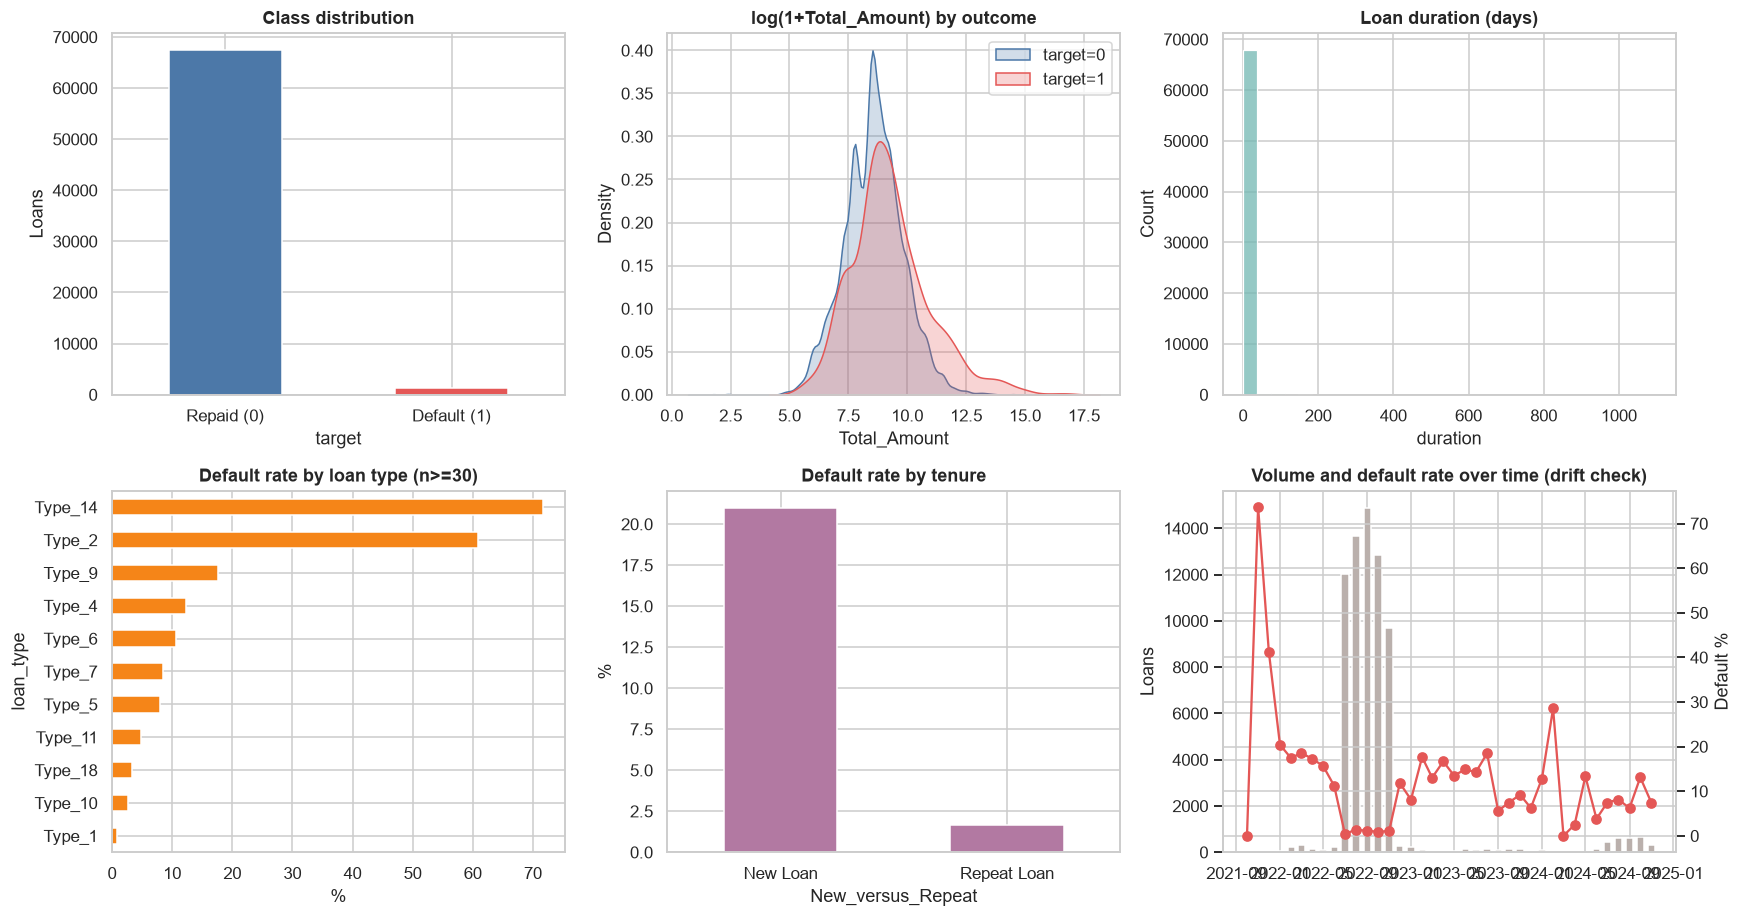

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
lab['target'].value_counts().sort_index().plot.bar(ax=ax[0, 0], color=['#4C78A8', '#E45756'])
ax[0, 0].set_title('Class distribution'); ax[0, 0].set_xticklabels(['Repaid (0)', 'Default (1)'], rotation=0); ax[0, 0].set_ylabel('Loans')
for k, c in [(0, '#4C78A8'), (1, '#E45756')]:
    sns.kdeplot(np.log1p(lab.loc[lab.target == k, 'Total_Amount']), ax=ax[0, 1], color=c, label=f'target={k}', fill=True, alpha=.25, common_norm=False)
ax[0, 1].set_title('log(1+Total_Amount) by outcome'); ax[0, 1].legend()
sns.histplot(lab['duration'], bins=30, ax=ax[0, 2], color='#72B7B2'); ax[0, 2].set_title('Loan duration (days)')
(lab.groupby('loan_type')['target'].agg(['mean', 'size']).query('size>=30')['mean'] * 100).sort_values().plot.barh(ax=ax[1, 0], color='#F58518')
ax[1, 0].set_title('Default rate by loan type (n>=30)'); ax[1, 0].set_xlabel('%')
(lab.groupby('New_versus_Repeat')['target'].mean() * 100).plot.bar(ax=ax[1, 1], color='#B279A2')
ax[1, 1].set_title('Default rate by tenure'); ax[1, 1].set_ylabel('%'); ax[1, 1].tick_params(axis='x', rotation=0)
m = lab.set_index('disbursement_date').resample('MS')['target'].agg(['mean', 'size'])
ax[1, 2].bar(m.index, m['size'], width=20, color='#BAB0AC'); ax[1, 2].set_ylabel('Loans'); ax2 = ax[1, 2].twinx()
ax2.plot(m.index, m['mean'] * 100, color='#E45756', marker='o'); ax2.set_ylabel('Default %'); ax[1, 2].set_title('Volume and default rate over time (drift check)')
plt.tight_layout(); savefig(fig, DIRS, 'plots_eda', 'eda_overview')

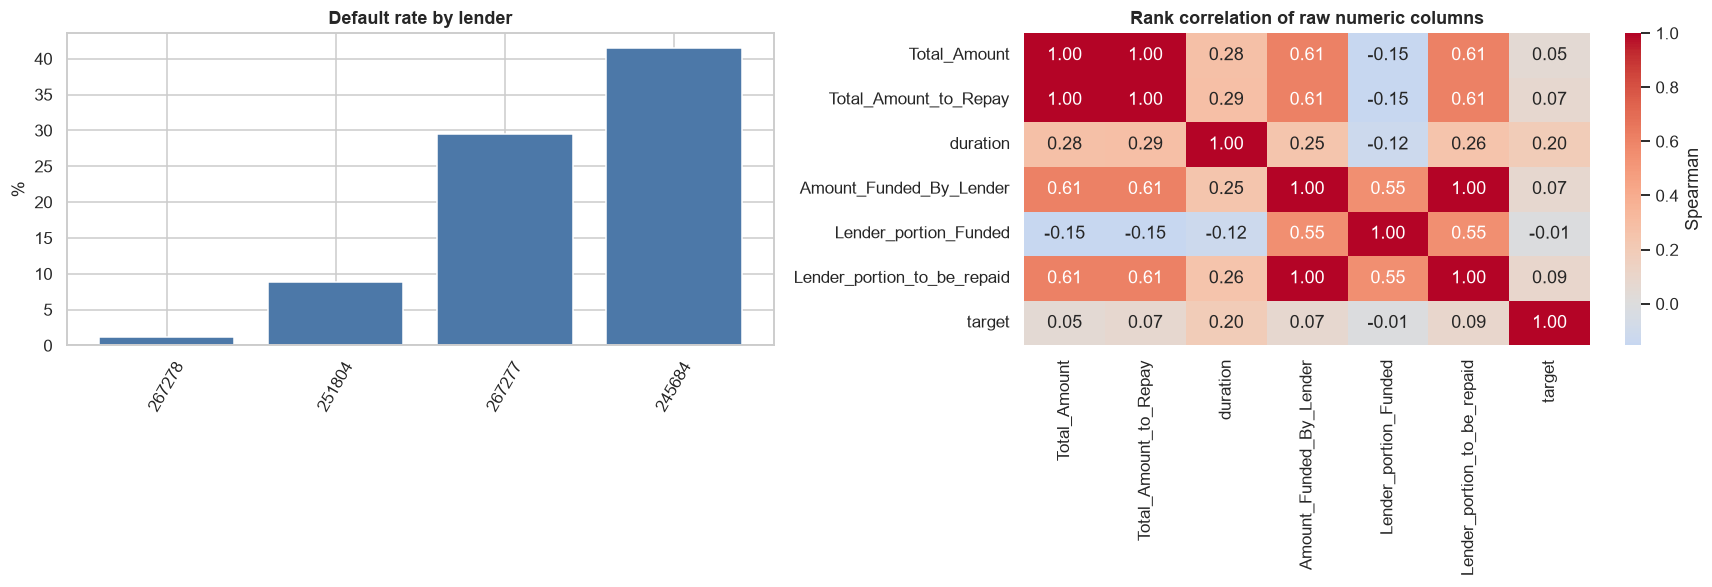

Highly collinear pairs (|rho|>0.9): [('Total_Amount', 'Total_Amount_to_Repay', np.float64(0.999)), ('Amount_Funded_By_Lender', 'Lender_portion_to_be_repaid', np.float64(0.999))]

Categorical cardinality: {'loan_type': 22, 'lender_id': 4, 'New_versus_Repeat': 2}
  loan_type: top-5 cover 98.7% of rows; 15 levels below MIN_CAT_FREQ=100 (pooled)
  lender_id: top-5 cover 100.0% of rows; 0 levels below MIN_CAT_FREQ=100 (pooled)
  New_versus_Repeat: top-5 cover 100.0% of rows; 0 levels below MIN_CAT_FREQ=100 (pooled)


,skew,pct_outside_1.5IQR,skew_after_log1p
Total_Amount,103.828,9.941,0.139
Total_Amount_to_Repay,104.579,10.155,0.147
duration,34.059,5.362,5.789
Amount_Funded_By_Lender,61.064,9.797,-1.190


In [7]:
g = lab.groupby('lender_id')['target'].agg(['mean', 'size']).sort_values('size', ascending=False).head(15)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ax[0].bar(g.index.astype(str), g['mean'] * 100, color='#4C78A8'); ax[0].set_title('Default rate by lender'); ax[0].set_ylabel('%'); ax[0].tick_params(axis='x', rotation=60)
num_raw = ['Total_Amount', 'Total_Amount_to_Repay', 'duration', 'Amount_Funded_By_Lender', 'Lender_portion_Funded', 'Lender_portion_to_be_repaid', 'target']
corr = lab[num_raw].corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1], cbar_kws={'label': 'Spearman'}); ax[1].set_title('Rank correlation of raw numeric columns')
plt.tight_layout(); savefig(fig, DIRS, 'plots_eda', 'eda_lender_corr')
hi = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > 0.9]
print('Highly collinear pairs (|rho|>0.9):', hi)

print('\nCategorical cardinality:', {c: lab[c].nunique() for c in CAT_COLS})
for c in CAT_COLS:
    vc = lab[c].value_counts()
    print(f'  {c}: top-5 cover {100*vc.head(5).sum()/len(lab):.1f}% of rows; {int((vc < CFG["MIN_CAT_FREQ"]).sum())} levels below MIN_CAT_FREQ={CFG["MIN_CAT_FREQ"]} (pooled)')
num_cols = ['Total_Amount', 'Total_Amount_to_Repay', 'duration', 'Amount_Funded_By_Lender']
q1, q3 = lab[num_cols].quantile(.25), lab[num_cols].quantile(.75); iqr = q3 - q1
skew_tbl = pd.DataFrame({'skew': lab[num_cols].skew(),
                         'pct_outside_1.5IQR': ((lab[num_cols] < q1 - 1.5 * iqr) | (lab[num_cols] > q3 + 1.5 * iqr)).mean() * 100,
                         'skew_after_log1p': np.log1p(lab[num_cols].clip(lower=0)).skew()})
display(skew_tbl.round(3)); skew_tbl.to_csv(DIRS['results'] / 'eda_skew.csv')

**Preprocessing decisions that follow from the EDA** (interpret against your own outputs):
1. **Imbalance** (~1:54): accuracy is meaningless; use PR-AUC, class weights / resampling inside folds, and a cost-based threshold.
2. **Skew**: amounts are extremely right-skewed; `log1p` removes almost all of it, so amounts enter models in logs and Task 1 is fitted on `log1p(Total_Amount)`.
3. **Cardinality**: `loan_type` has a long tail of rare levels, so levels under `MIN_CAT_FREQ` are pooled in the one-hot encoder (unseen levels at scoring time go to the same bucket).
4. **Drift**: the monthly default rate moves, which motivates the temporal hold-out and forward-chaining CV in 02.
5. **Collinearity**: amount, repayment amount and funded amount are almost perfectly correlated, which matters for linear models (regularisation) and for Task 1 (these columns are excluded).
6. **Outliers are kept**: large loans are legitimate and are where losses sit; logs and trees handle them.

## 4. Feature engineering (Part B.2)
| Group | Features | Why predictive | Definition |
|---|---|---|---|
| base | `loan_type`, `lender_id`, `duration`, `New_versus_Repeat` | Product, funder, term and tenure drive risk | raw |
| calendar | month, quarter, weekday, day-of-month, month-end flag, due weekday, due-on-weekend | Pay cycles; weekend due dates add repayment friction | from dates |
| terms (Task 2 only) | `log_amount`, `fee_rate`, `daily_fee_rate`, funded and repay shares, `amount_vs_prior_mean` | Price and size of credit; a jump over past loan size signals stretch | `fee_rate=(Repay-Amount)/Amount`, `daily_fee_rate=fee_rate/duration` |
| history | prior loans, days since last loan, prior mean/last amount, resolved prior loans, prior defaults, prior default rate | Past behaviour is the strongest classical credit signal | backward `merge_asof`, exact matches excluded, outcomes counted only after `due_date`; counts, gaps and amounts enter models as `log1p` (heavy tails) |
| macro (joined, **not a model input**) | inflation, exchange rate, deposit/lending rates, spread, real rate, unemployment | Repayment capacity moves with prices and rates | `economic_indicators.csv` reshaped wide→long, joined on (country, year−1); used for the Kenya vs Ghana contrast (04) and tested by ablation (02) |

Learned statistics (medians, scaling, encoders) are **not** computed here; they live in the pipelines of 02/03.

In [8]:
print({k: v for k, v in ds.groups.items()})
print('\nSupplied tenure vs engineered "has prior loan in Train":')
display(pd.crosstab(feat['New_versus_Repeat'], feat['no_prior_loans'].map({1: 'no prior in data', 0: 'prior in data'})))
print('Share of loans with >=1 resolved prior loan: %.1f%%' % (100 * (feat['n_resolved_prior'] > 0).mean()))
display(feat[ds.all_clf].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(3))
raw_hist = ['n_prior_loans', 'n_prior_defaults', 'days_since_last_loan', 'prior_mean_amount', 'last_amount']
print('Skew of raw history columns (why they enter models as log1p):', feat[raw_hist].skew().round(1).to_dict())

{'base': ['duration', 'loan_type', 'lender_id', 'New_versus_Repeat'], 'calendar': ['disb_month', 'disb_quarter', 'disb_dow', 'disb_dom', 'disb_month_end', 'due_dow', 'due_weekend'], 'terms': ['log_amount', 'fee_rate', 'daily_fee_rate', 'lender_funded_share', 'lender_repay_share', 'Lender_portion_Funded', 'amount_vs_prior_mean'], 'history': ['log_n_prior_loans', 'no_prior_loans', 'log_days_since_last_loan', 'log_prior_mean_amount', 'log_last_amount', 'log_n_resolved_prior', 'log_n_prior_defaults', 'prior_default_rate'], 'macro': ['macro_deposit_interest_rate', 'macro_inflation_consumer_prices_annual', 'macro_interest_rate_spread_lending_rate_minus_deposit_rate', 'macro_lending_interest_rate', 'macro_official_exchange_rate_lcu_per_us_period_average', 'macro_real_interest_rate', 'macro_unemployment_rate']}

Supplied tenure vs engineered "has prior loan in Train":


no_prior_loans,no prior in data,prior in data
New_versus_Repeat,,
New Loan,567,0
Repeat Loan,6792,61295


Share of loans with >=1 resolved prior loan: 82.5%


,count,mean,std,min,50%,max
duration,68654.0,8.545,13.343,1.000,7.000,1096.000
disb_month,68654.0,8.783,1.631,1.000,9.000,12.000
disb_quarter,68654.0,3.309,0.573,1.000,3.000,4.000
disb_dow,68654.0,2.496,1.794,0.000,2.000,6.000
disb_dom,68654.0,16.346,8.727,1.000,17.000,31.000
disb_month_end,68654.0,0.227,0.419,0.000,0.000,1.000
due_dow,68654.0,2.531,1.808,0.000,3.000,6.000
due_weekend,68654.0,0.198,0.399,0.000,0.000,1.000
log_amount,68654.0,8.575,1.264,1.099,8.566,16.951
fee_rate,68654.0,0.022,0.056,-1.000,0.008,2.165


Skew of raw history columns (why they enter models as log1p): {'n_prior_loans': 3.5, 'n_prior_defaults': 30.3, 'days_since_last_loan': 18.1, 'prior_mean_amount': 29.2, 'last_amount': 44.2}


In [9]:
# Time-safety unit test: recompute history by brute force for a random sample and compare.
bad = brute_force_history_check(feat, lab, n=300, seed=SEED, grace_days=CFG['GRACE_DAYS'])
print(f'History brute-force check on 300 loans: {bad} mismatches (must be 0)')
assert bad == 0, 'Time-safe history is inconsistent'

History brute-force check on 300 loans: 0 mismatches (must be 0)


In [10]:
# Macro join check: which indicator values does each period of the data see?
if ds.groups['macro']:
    mt = feat.assign(year=feat.disbursement_date.dt.year).groupby('year')[ds.groups['macro']].first().T
    display(mt.round(2))
    print('Distinct values per macro indicator in the dev split:', dev[ds.groups['macro']].nunique().to_dict())
    print('Share of test loans whose macro values never occur in dev: %.1f%%' % (100 * (~ds.test[ds.groups['macro'][0]].isin(dev[ds.groups['macro'][0]].unique())).mean()))

year,2021,2022,2023,2024
macro_deposit_interest_rate,6.97,6.69,7.15,9.17
macro_inflation_consumer_prices_annual,5.41,6.11,7.66,7.67
macro_interest_rate_spread_lending_rate_minus_deposit_rate,5.03,5.39,5.19,4.42
macro_lending_interest_rate,12.00,12.08,12.34,13.59
macro_official_exchange_rate_lcu_per_us_period_average,106.45,109.64,117.87,139.85
macro_real_interest_rate,6.71,7.43,5.97,6.55
macro_unemployment_rate,5.62,5.69,5.80,5.68


Distinct values per macro indicator in the dev split: {'macro_deposit_interest_rate': 2, 'macro_inflation_consumer_prices_annual': 2, 'macro_interest_rate_spread_lending_rate_minus_deposit_rate': 2, 'macro_lending_interest_rate': 2, 'macro_official_exchange_rate_lcu_per_us_period_average': 2, 'macro_real_interest_rate': 2, 'macro_unemployment_rate': 2}
Share of test loans whose macro values never occur in dev: 30.6%


**Decision: macro indicators are joined but not used as model inputs** (`CFG['USE_MACRO_FEATURES'] = False`). Train is
Kenya-only and almost all of it falls in 2022, so after the one-year lag the dev split contains only **two** values of each
indicator: the columns can only act as a year flag, not teach an economic effect. Later loans (2023–24) carry values the
models never saw, so linear models extrapolate and trees clamp. The join is still used where it is informative: the
Kenya vs Ghana macro contrast (04) and the ablation in 02 (E5, `+macro`), which documents the effect of adding them.

## 5. Cost matrix in money (Part A.3)
Per-loan costs, computed from each loan's own principal and fee (the dev split, so no test information is used):

* **False negative** (approve, borrower defaults): `FN_i = principal_i × (1 − recovery) + principal_i × collection_cost_rate`
* **False positive** (decline a good borrower): `FP_i = fee_i = Total_Amount_to_Repay_i − Total_Amount_i` (forgone income; the
  borrower is also denied credit, reported separately as an access cost in 04)
* With a calibrated PD *p*, declining is cheaper when `p·FN > (1−p)·FP`, i.e. **decline when `p > FP / (FP + FN)`**.

> **Assumptions to justify in the report.** `RECOVERY_RATE` and `COLLECTION_COST_RATE` in `src/prosit2/config.py` are
> placeholders. Amounts are in **Kenyan shillings (KES)**; set `FX_TO_GHS` (with source and date) to report in cedis.

In [11]:
fn_dev, fp_dev = cost_vectors(dev, cfg=CFG)
p_star = analytic_threshold(fn_dev, fp_dev)
cm = pd.DataFrame({f'mean principal ({CUR})': [dev.Total_Amount.mean() * FX], f'median principal ({CUR})': [dev.Total_Amount.median() * FX],
                   f'mean fee income = FP cost ({CUR})': [fp_dev.mean() * FX], f'mean FN cost ({CUR})': [fn_dev.mean() * FX],
                   'FN:FP ratio (reported after money)': [fn_dev.mean() / max(fp_dev.mean(), 1e-9)], 'analytic threshold p*': [p_star]})
display(cm.round(3)); cm.to_csv(DIRS['results'] / 'cost_matrix.csv', index=False)
rows = []
for rec in (0.0, CFG['RECOVERY_RATE'], 0.4):
    for coll in (CFG['COLLECTION_COST_RATE'], 0.15):
        fn_s, fp_s = cost_vectors(dev, recovery=rec, coll=coll, cfg=CFG)
        rows.append({'recovery': rec, 'collection cost rate': coll, f'mean FN ({CUR})': fn_s.mean() * FX, f'mean FP ({CUR})': fp_s.mean() * FX,
                     'p*': analytic_threshold(fn_s, fp_s)})
sens = pd.DataFrame(rows); display(sens.round(4)); sens.to_csv(DIRS['results'] / 'cost_matrix_sensitivity.csv', index=False)
print(f'Base default rate on dev = {dev.target.mean():.4f}. If p* is close to the base rate, only a model that separates risk well '
      'can beat "approve everyone"; that is a finding, not a bug.')

,mean principal (KES),median principal (KES),mean fee income = FP cost (KES),mean FN cost (KES),FN:FP ratio (reported after money),analytic threshold p*
0,11218.509,5198.0,254.895,9872.288,38.731,0.025


,recovery,collection cost rate,mean FN (KES),mean FP (KES),p*
0,0.0,0.08,12115.9898,254.8951,0.0206
1,0.0,0.15,12901.2854,254.8951,0.0194
2,0.2,0.08,9872.2880,254.8951,0.0252
3,0.2,0.15,10657.5836,254.8951,0.0234
4,0.4,0.08,7628.5862,254.8951,0.0323
5,0.4,0.15,8413.8818,254.8951,0.0294


Base default rate on dev = 0.0129. If p* is close to the base rate, only a model that separates risk well can beat "approve everyone"; that is a finding, not a bug.


**Reading the cost matrix.** The fee is small relative to principal (short loans, low fees), so a missed default costs many
times a wrongly declined good borrower and `p*` is only a few percent. Notebook 02 picks the actual operating threshold on
*calibrated* out-of-fold probabilities by minimising expected cost subject to the 80 % approval constraint, and repeats the
choice under the alternative recovery assumptions above.